<a href="https://colab.research.google.com/github/GlumakovaDA/-_-_-/blob/main/%D0%A4%D0%BE%D1%80%D0%B5%D0%BB%D1%8C_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
install.packages("lterdatasampler")
library(lterdatasampler)
head(and_vertebrates)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



,year,sitecode,section,reach,pass,unitnum,unittype,vert_index,pitnumber,species,length_1_mm,length_2_mm,weight_g,clip,sampledate,notes
,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<date>,<chr>
1,1987,MACKCC-L,CC,L,1,1,R,1,NA,Cutthroat trout,58,NA,1.75,NONE,1987-10-07,NA
2,1987,MACKCC-L,CC,L,1,1,R,2,NA,Cutthroat trout,61,NA,1.95,NONE,1987-10-07,NA
3,1987,MACKCC-L,CC,L,1,1,R,3,NA,Cutthroat trout,89,NA,5.60,NONE,1987-10-07,NA
4,1987,MACKCC-L,CC,L,1,1,R,4,NA,Cutthroat trout,58,NA,2.15,NONE,1987-10-07,NA
5,1987,MACKCC-L,CC,L,1,1,R,5,NA,Cutthroat trout,93,NA,6.90,NONE,1987-10-07,NA
6,1987,MACKCC-L,CC,L,1,1,R,6,NA,Cutthroat trout,86,NA,5.90,NONE,1987-10-07,NA


In [2]:
library(dplyr)
library(tidyr)

# уникальные виды и количество наблюдений по каждому
and_vertebrates %>%
  count(species, sort = TRUE)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




species,n
<chr>,<int>
Cutthroat trout,20433
Coastal giant salamander,11758
Cascade torrent salamander,15
NA,3


In [3]:
salamanders <- and_vertebrates %>%
  filter(species == "Coastal giant salamander")
cat("Всего строк по виду:", nrow(salamanders), "\n")
cat("Пропусков в length_1_mm:", sum(is.na(salamanders$length_1_mm)), "\n")
cat("Пропусков в weight_g:   ", sum(is.na(salamanders$weight_g)), "\n")

Всего строк по виду: 11758 
Пропусков в length_1_mm: 9 
Пропусков в weight_g:    5420 


In [4]:
trout <- and_vertebrates %>%
  filter(species == "Cutthroat trout")
cat("Всего строк по виду:", nrow(trout), "\n")
cat("Пропусков в length_1_mm:", sum(is.na(trout$length_1_mm)), "\n")
cat("Пропусков в weight_g:   ", sum(is.na(trout$weight_g)), "\n")

Всего строк по виду: 20433 
Пропусков в length_1_mm: 5 
Пропусков в weight_g:    7839 


In [7]:
# очистка от пропусков в нужных переменных
tr <- trout %>%
  drop_na(length_1_mm, weight_g)

cat("Осталось после очистки:", nrow(sal), "строк\n\n")

Осталось после очистки: 12592 строк



опсиательные статистики

In [15]:
desc_length <- tr %>%
  summarise(
    n      = sum(!is.na(length_1_mm)),
    mean   = mean(length_1_mm),
    median = median(length_1_mm),
    sd     = sd(length_1_mm),
    var    = var(length_1_mm),
    min    = min(length_1_mm),
    q25    = quantile(length_1_mm, .25),
    q75    = quantile(length_1_mm, .75),
    max    = max(length_1_mm),
    MAD    = mad(length_1_mm)
  ) %>%
  mutate(variable = "length_1_mm", .before = 1)

desc_weight <- tr %>%
  summarise(
    n      = sum(!is.na(weight_g)),
    mean   = mean(weight_g),
    median = median(weight_g),
    sd     = sd(weight_g),
    var    = var(weight_g),
    min    = min(weight_g),
    q25    = quantile(weight_g, .25),
    q75    = quantile(weight_g, .75),
    max    = max(weight_g),
    MAD    = mad(weight_g)
  ) %>%
  mutate(variable = "weight_g", .before = 1)

desc <- bind_rows(desc_length, desc_weight)

desc_t <- as.data.frame(t(desc[, -1]))
colnames(desc_t) <- desc$variable

print(round(desc_t, 3))

       length_1_mm  weight_g
n        12592.000 12592.000
mean        83.029     8.844
median      85.000     6.150
sd          35.157     9.876
var       1236.002    97.540
min         23.000     0.090
q25         49.000     1.200
q75        109.000    12.900
max        253.000   104.000
MAD         47.443     7.487


1. mean и median  Среднее и медиана по длине близки → распределение длины почти симметричное
2. mean и median Среднее заметно выше медианы (по весу) → распределение веса скошено вправо. много мелких рыбок и немного крупных взрослых особей
3. sd Длина: 35.16 мм — типичная рыба отклоняется от средней длины примерно на 3.5 см., Вес: 9.88 г — типичное отклонение по весу почти 10 г. (в относительных величинах (sd / mean) длина даёт ≈42%, вес ≈112%. вес «разбросан» относительно среднего почти в 3 раза сильнее, чем длина.)
4. q25  оба квартиля низкие относительно медиан — это подтверждает, что в выборке много мелких особей.
5. q75  размах (q25–q75) по длине 49–109 мм, по весу 1.2–12.9 г. По весу все еще смещён к нижнему краю
6. сравнение sd и MAD: по весу выбросов больше, чем по длине.

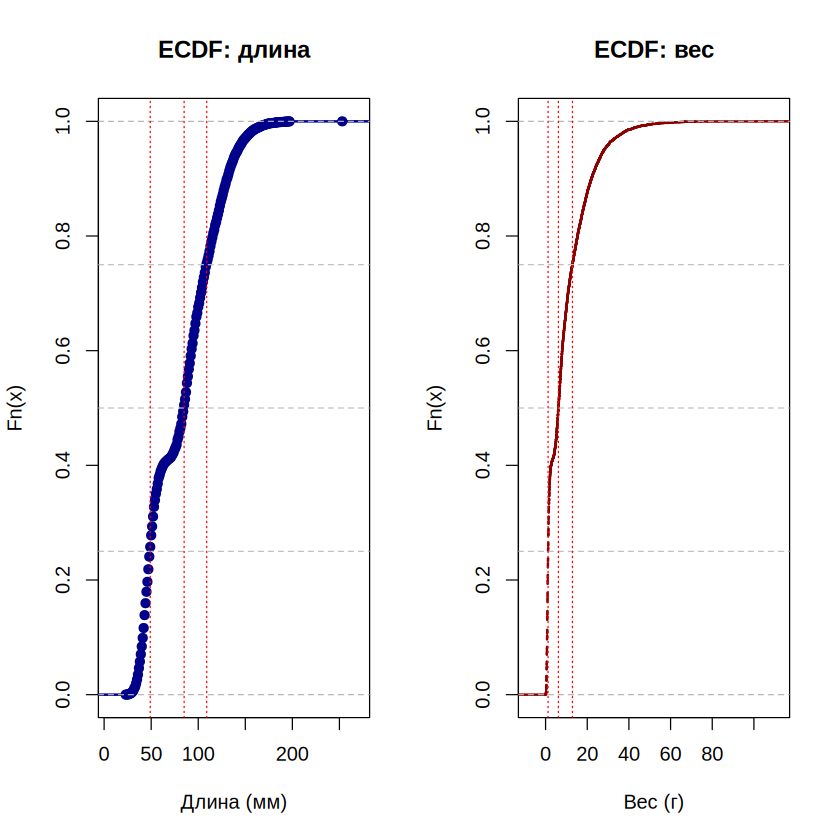

In [18]:
par(mfrow = c(1, 2))

plot(ecdf(tr$length_1_mm), main = "ECDF: длина",
     xlab = "Длина (мм)", ylab = "Fn(x)", col = "darkblue", lwd = 2)
abline(h = c(0.25, 0.5, 0.75), col = "grey", lty = 2)
abline(v = quantile(tr$length_1_mm, c(.25, .5, .75)), col = "red", lty = 3)

plot(ecdf(tr$weight_g), main = "ECDF: вес",
     xlab = "Вес (г)", ylab = "Fn(x)", col = "darkred", lwd = 2)
abline(h = c(0.25, 0.5, 0.75), col = "grey", lty = 2)
abline(v = quantile(tr$weight_g, c(.25, .5, .75)), col = "red", lty = 3)

par(mfrow = c(1, 1))

1. Длина

Начинается около 0 при x ≈ 25 мм — почти нет рыб короче 25 мм

Быстро растёт в интервале 50–150 мм — там сосредоточена основная масса рыб

Пересечение с уровнем 0.5 (медиана) — примерно на 85 мм совпадает с таблицей

2. Вес

Первые несколько граммов забирают почти половину графика — к 6 г кривая пересекает 0.5 (медиана)

К 13 г — пересекает 0.75, то есть 75% рыб весят ≤ 12.9 г

Дальше кривая становится почти горизонтальной и медленно ползёт до 1.0 к 104 г

In [20]:
# Корреляция между длиной и весом

cat("Pearson: ",  round(cor(tr$length_1_mm, tr$weight_g, method = "pearson"),  3), "\n")
cat("Spearman:", round(cor(tr$length_1_mm, tr$weight_g, method = "spearman"), 3), "\n")

Pearson:  0.912 
Spearman: 0.992 



Call:
lm(formula = weight_g ~ length_1_mm, data = tr)

Residuals:
    Min      1Q  Median      3Q     Max 
-21.759  -2.854  -0.272   1.880 104.900 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -12.428684   0.092587  -134.2   <2e-16 ***
length_1_mm   0.256203   0.001027   249.5   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.051 on 12590 degrees of freedom
Multiple R-squared:  0.8318,	Adjusted R-squared:  0.8318 
F-statistic: 6.225e+04 on 1 and 12590 DF,  p-value: < 2.2e-16



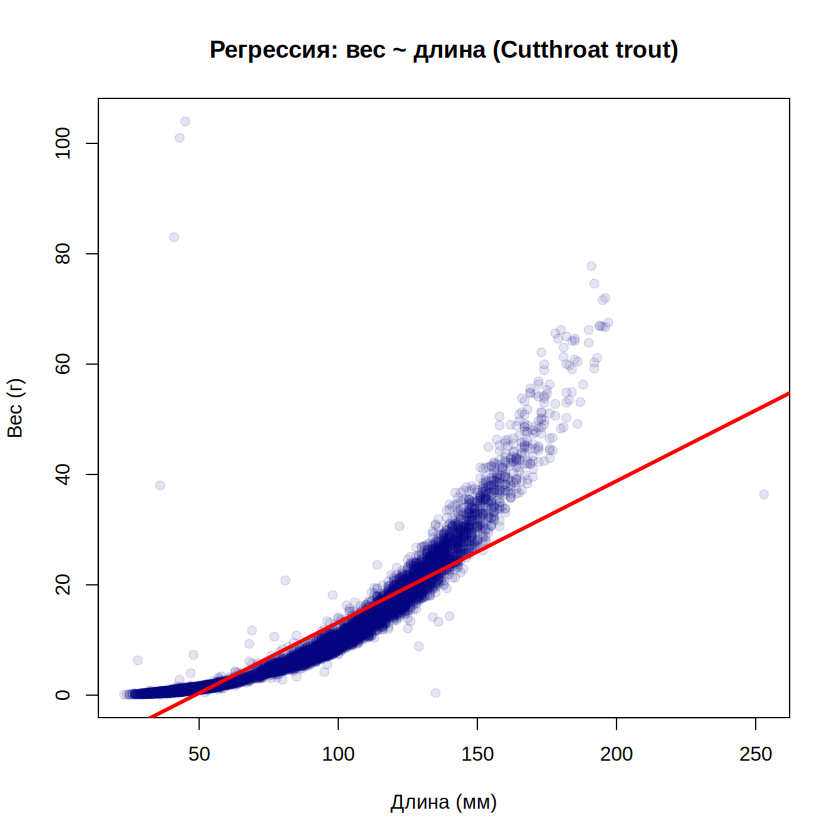

In [24]:


model <- lm(weight_g ~ length_1_mm, data = tr)
print(summary(model))

# График рассеяния + линия регрессии
plot(tr$length_1_mm, tr$weight_g,
     main = "Регрессия: вес ~ длина (Cutthroat trout)",
     xlab = "Длина (мм)", ylab = "Вес (г)",
     pch = 19, col = rgb(0, 0, 0.5, 0.1))
abline(model, col = "red", lwd = 3)

1Q = −2.85 — 25% остатков ниже −2.85 г.

Median = −0.27 — медиана остатков почти ноль. модель не завышает и не занижает систематически.

3Q = 1.88 — 75% остатков ниже 1.88 г. То есть половина ошибок лежит в диапазоне примерно ±2–3 г.

медиана остатков ≈ 0 и симметричные квартили (−2.85 / +1.88) те для большинства рыб модель работает нормально


Call:
lm(formula = log(weight_g) ~ log(length_1_mm), data = tr)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.0916 -0.0710  0.0021  0.0670  4.8120 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)      -11.283184   0.013991  -806.5   <2e-16 ***
log(length_1_mm)   2.947540   0.003219   915.7   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.1619 on 12590 degrees of freedom
Multiple R-squared:  0.9852,	Adjusted R-squared:  0.9852 
F-statistic: 8.384e+05 on 1 and 12590 DF,  p-value: < 2.2e-16



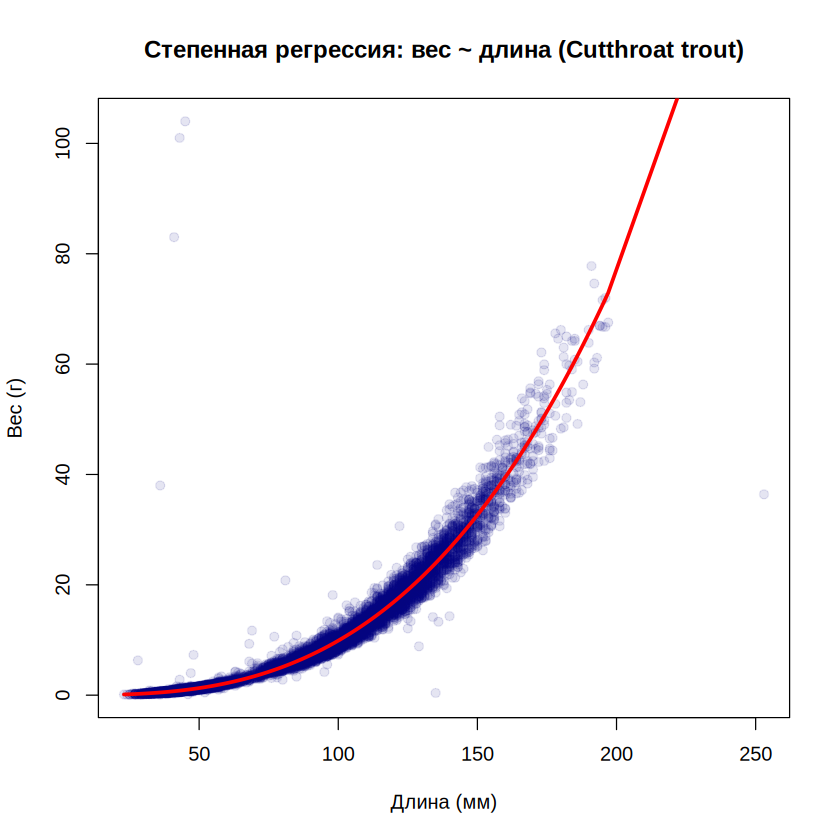

In [27]:
model_pow <- lm(log(weight_g) ~ log(length_1_mm), data = tr)
print(summary(model_pow))

# График рассеяния + кривая регрессии
tr_sorted <- tr[order(tr$length_1_mm), ]
pred_pow <- exp(predict(model_pow, newdata = tr_sorted))

plot(tr$length_1_mm, tr$weight_g,
     main = "Степенная регрессия: вес ~ длина (Cutthroat trout)",
     xlab = "Длина (мм)", ylab = "Вес (г)",
     pch = 19, col = rgb(0, 0, 0.5, 0.1))
lines(tr_sorted$length_1_mm, pred_pow, col = "red", lwd = 3)

In [33]:

# Линейная модель
model_lin <- lm(weight_g ~ length_1_mm, data = tr)

# Степенная модель
model_pow <- lm(log(weight_g) ~ log(length_1_mm), data = tr)

pred_pow_orig <- exp(predict(model_pow))
ss_res <- sum((tr$weight_g - pred_pow_orig)^2)
ss_tot <- sum((tr$weight_g - mean(tr$weight_g))^2)
r2_pow_orig <- 1 - ss_res / ss_tot

# Сравнительная таблица
comparison <- data.frame(
  Модель      = c("Линейная: W = a + b·L",
                  "Степенная: W = a · L^b"),
  Формула     = c(paste0("W = ", round(coef(model_lin)[1], 2),
                         " + ", round(coef(model_lin)[2], 4), "·L"),
                  paste0("W = ", round(exp(coef(model_pow)[1]), 6),
                         " · L^", round(coef(model_pow)[2], 3))),
  R2          = c(round(summary(model_lin)$r.squared, 4),
                  round(r2_pow_orig, 4)),
  RSE         = c(round(summary(model_lin)$sigma, 3),
                  round(sqrt(ss_res / (nrow(tr) - 2)), 3))
)

print(comparison, row.names = FALSE)


                 Модель               Формула     R2   RSE
  Линейная: W = a + b·L W = -12.43 + 0.2562·L 0.8318 4.051
 Степенная: W = a · L^b W = 1.3e-05 · L^2.948 0.9462 2.290
